# 03 · Model Training, Hyper-parameter Tuning and Evaluation
**AAI-540 Group 3 — CloudTrail Suspicious-Activity Classifier**

| | |
|---|---|
| **Goal** | Train the single production model required by the design document — a **binary XGBoost classifier** — with SageMaker training jobs, tune it with **SageMaker Automatic Model Tuning**, and evaluate it honestly on an untouched future period. |
| **Input (S3)** | `features/feature_mart.parquet` (notebook 02) |
| **Output (S3)** | `model-input/` (encoded train / validation / test CSVs + `encoder.json`) · `training/` (model artefacts) · `training/evaluation/evaluation.json` |
| **Next** | `04_registry_deployment_inference.ipynb` |

**Studio instance:** `ml.t3.medium`. Training itself runs on separate `ml.m5.large` training-job instances that SageMaker starts and stops automatically (billed per second).

## 1. Setup

In [1]:
%%capture pip_log
# Install the project's pinned libraries (run once per kernel, BEFORE any other import).
# The pin keeps the SageMaker Python SDK on v2, which all notebooks in this repo use.
# Output is captured to keep the notebook clean; run print(pip_log.stdout) to see it.
# (Warnings about sagemaker-core / sagemaker-mlops conflicts refer to Studio's pre-installed
#  SDK v3 packages, which this project does not use.)
%pip install -q -r ../requirements.txt

In [2]:
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # shared project package: src/cloudtrail_mlops
DATA_DIR = Path.home() / "cloudtrail-data"           # local working copy, outside the git repo
DATA_DIR.mkdir(exist_ok=True)
os.environ["SAGEMAKER_SUPPRESS_V2_WARNING"] = "1"         # we intentionally pin SDK v2 (see requirements.txt)

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sagemaker
from sagemaker.estimator import Estimator
from sagemaker.inputs import TrainingInput
from sagemaker.tuner import ContinuousParameter, HyperparameterTuner, IntegerParameter
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from cloudtrail_mlops import aws, config, dataset, evaluation, model
from cloudtrail_mlops.plots import BLUE, MUTED, NORMAL, ORANGE, SUSPICIOUS, setup_style

setup_style()
ctx = aws.get_context()
sm_client = ctx.session.sagemaker_client
TRAIN_INSTANCE = "ml.m5.large"

MART_PATH = DATA_DIR / "features" / "feature_mart.parquet"
if not MART_PATH.exists():
    ctx.session.download_data(str(MART_PATH.parent), bucket=ctx.bucket, key_prefix=ctx.prefix("features") + "/feature_mart.parquet")
mart = dataset.load_mart(MART_PATH)
print(f"Feature mart: {mart.shape[0]:,} windows, {mart.actor_id.nunique()} actors")

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml
Feature mart: 75,609 windows, 185 actors


## 2. Training data: chronological split and encoding
* **Split by time, never randomly.** Train = Feb 2017 – Dec 2018, validation = 2019, test = 2020. A random split would let the model see the future of the same attack burst it is tested on and overstate performance.
* **1-day embargo** before each cut: the label looks 30 minutes ahead, so windows right before a cut are dropped.
* **Validation (2019)** is used for early stopping, hyper-parameter tuning and the alert thresholds. **Test (2020)** is used **once**, for the final report and the release gate.
* **Encoding:** the 3 categorical features are one-hot encoded with a vocabulary learned on the training split only (categories seen < 20 times → `__other__`). The vocabulary is saved to `encoder.json` and reused at inference time, so training-time and serving-time encoding are identical.
* **Format:** the SageMaker built-in XGBoost algorithm reads headerless CSV with the label in the first column.

In [3]:
assert not dataset.leakage_violations(config.FEATURE_COLUMNS), "label-defining columns in the model inputs!"

MODEL_INPUT_DIR = DATA_DIR / "model-input"
prepared = dataset.prepare_model_inputs(mart, MODEL_INPUT_DIR)
splits, encoder = prepared["splits"], prepared["encoder"]
print(f"Encoded feature vector: {len(encoder.feature_names)} columns "
      f"({len(config.NUMERIC_FEATURES)} numeric + {len(encoder.feature_names) - len(config.NUMERIC_FEATURES)} one-hot)")
prepared["summary"]

Encoded feature vector: 70 columns (35 numeric + 35 one-hot)


,split,rows,start,end,positives,prevalence,actors
0,train,35768,2017-02-12 19:55:00+00:00,2018-12-30 23:15:00+00:00,224,0.00626,64
1,validation,21855,2019-01-01 00:05:00+00:00,2019-12-30 23:50:00+00:00,68,0.00311,58
2,test,17908,2020-01-01 00:35:00+00:00,2020-10-07 20:30:00+00:00,101,0.00564,81


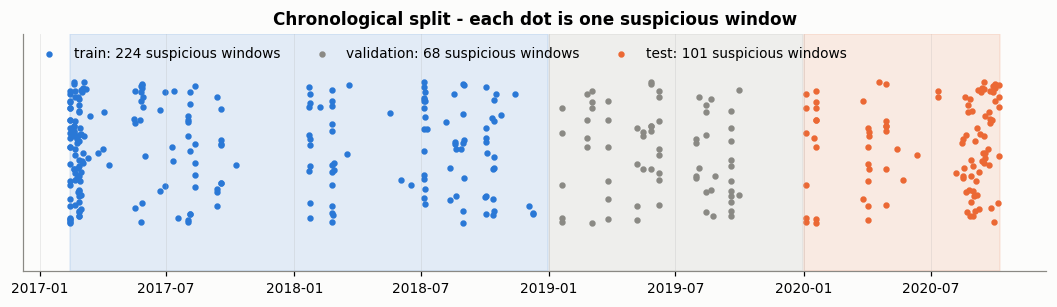

In [4]:
fig, ax = plt.subplots(figsize=(12, 2.8))
for name, colour in (("train", BLUE), ("validation", MUTED), ("test", ORANGE)):
    frame = splits[name]
    ax.axvspan(frame.window_start.min(), frame.window_start.max(), color=colour, alpha=0.12)
    positives = frame[frame[config.TARGET_COLUMN] == 1]
    ax.scatter(positives.window_start, np.random.default_rng(0).uniform(0.2, 0.8, len(positives)),
               s=10, color=colour, label=f"{name}: {len(positives)} suspicious windows")
ax.set(title="Chronological split - each dot is one suspicious window", yticks=[], ylim=(0, 1))
ax.legend(loc="upper left", ncol=3)
plt.show()

In [5]:
model_input_uri = ctx.session.upload_data(str(MODEL_INPUT_DIR), bucket=ctx.bucket, key_prefix=ctx.prefix("model_input"))
aws.save_state(ctx, model_input_uri=model_input_uri)
train_input = TrainingInput(f"{model_input_uri}/train", content_type="text/csv")
validation_input = TrainingInput(f"{model_input_uri}/validation", content_type="text/csv")
print("Model inputs uploaded to", model_input_uri)

Model inputs uploaded to s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/model-input


## 3. Baselines — how much does a model add?
Before training XGBoost we score the validation year with three simple references. If XGBoost cannot clearly beat them, it is not worth deploying.
* **Prior only** — predicts the base rate for everyone (average precision = prevalence).
* **One-line rule** — rank windows by `write_rate_current` (share of state-changing calls).
* **Logistic regression** — a linear model on the same encoded features.

In [6]:
X = prepared["encoded"]
y = prepared["labels"]
baseline_scores = {
    "Prior only": DummyClassifier(strategy="prior").fit(X["train"], y["train"]).predict_proba(X["validation"])[:, 1],
    "Rule: write_rate_current": X["validation"]["write_rate_current"].to_numpy(),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.1, max_iter=2000))
                           .fit(X["train"], y["train"]).predict_proba(X["validation"])[:, 1],
}
baselines = pd.DataFrame({name: {"validation ROC-AUC": roc_auc_score(y["validation"], s),
                                 "validation AP": average_precision_score(y["validation"], s)}
                          for name, s in baseline_scores.items()}).T
baselines["AP lift"] = baselines["validation AP"] / y["validation"].mean()
baselines.round(4)

,validation ROC-AUC,validation AP,AP lift
Prior only,0.5000,0.0031,1.0000
Rule: write_rate_current,0.6480,0.0047,1.5016
Logistic regression,0.9167,0.1038,33.3460


## 4. Train XGBoost with a SageMaker training job
We use the **SageMaker built-in XGBoost algorithm** (container version 1.7-1): no training script to maintain, the model artefact is directly deployable, and every run is tracked in SageMaker (Studio → *Jobs → Training*).

Key settings (from `config.DEFAULT_HYPERPARAMETERS`):
* `objective = binary:logistic` → output is a probability of "suspicious";
* `eval_metric = aucpr` → precision-recall AUC on the validation channel, the right metric for a ~0.5 % positive class;
* `early_stopping_rounds = 40` → stop when validation AUC-PR stops improving (limits over-fitting);
* `max_depth = 4`, `subsample`, `colsample_bytree`, `min_child_weight`, `lambda` → regularisation (only a few hundred positive windows exist);
* `scale_pos_weight = 5` → up-weights the rare positive class.

In [7]:
image_uri = sagemaker.image_uris.retrieve("xgboost", region=ctx.region, version=config.XGBOOST_VERSION)
estimator = Estimator(
    image_uri=image_uri, role=ctx.role, instance_count=1, instance_type=TRAIN_INSTANCE,
    output_path=ctx.s3_uri("training", "models"), base_job_name="ct-xgb-baseline",
    hyperparameters=config.DEFAULT_HYPERPARAMETERS, sagemaker_session=ctx.session,
)
estimator.fit({"train": train_input, "validation": validation_input}, wait=True, logs=False)

def final_metrics(job_name):
    job = sm_client.describe_training_job(TrainingJobName=job_name)
    return {m["MetricName"]: round(m["Value"], 4) for m in job.get("FinalMetricDataList", [])}, job

default_metrics, default_job = final_metrics(estimator.latest_training_job.name)
print("Training job:", default_job["TrainingJobName"], "|", default_job["TrainingJobStatus"],
      f"| billable seconds: {default_job.get('BillableTimeInSeconds')}")
print("Final metrics:", default_metrics)

INFO:sagemaker:Creating training-job with name: ct-xgb-baseline-2026-10-17-22-09-40-161



2026-10-17 22:09:41 Starting - Starting the training job..
2026-10-17 22:09:57 Starting - Preparing the instances for training....
2026-10-17 22:10:24 Downloading - Downloading input data..................
2026-10-17 22:12:00 Downloading - Downloading the training image..
2026-10-17 22:12:15 Training - Training image download completed. Training in progress...
2026-10-17 22:12:31 Uploading - Uploading generated training model...
2026-10-17 22:12:49 Completed - Training job completed
Training job: ct-xgb-baseline-2026-10-17-22-09-40-161 | Completed | billable seconds: 144
Final metrics: {'validation:aucpr': 0.2797, 'train:aucpr': 0.838}


## 5. Hyper-parameter tuning (SageMaker Automatic Model Tuning)
Bayesian search over 7 hyper-parameters, **maximising validation AUC-PR**. The test year is never used here. `max_jobs = 10` with 2 in parallel keeps the cost to a few cents and the wall-clock time to ~15–20 minutes.

In [9]:
RUN_TUNING = True   # set False to skip tuning and keep the default hyper-parameters

if RUN_TUNING:
    static = {k: v for k, v in config.DEFAULT_HYPERPARAMETERS.items()
              if k in ("objective", "eval_metric", "num_round", "early_stopping_rounds", "scale_pos_weight")}
    # scale_pos_weight is not tunable in the built-in XGBoost container, so it stays fixed at the config value
    tuning_estimator = Estimator(image_uri=image_uri, role=ctx.role, instance_count=1, instance_type=TRAIN_INSTANCE,
                                 output_path=ctx.s3_uri("training", "tuning"), hyperparameters=static,
                                 sagemaker_session=ctx.session)
    tuner = HyperparameterTuner(
        estimator=tuning_estimator,
        objective_metric_name="validation:aucpr", objective_type="Maximize",
        hyperparameter_ranges={
            "eta": ContinuousParameter(0.01, 0.3, scaling_type="Logarithmic"),
            "max_depth": IntegerParameter(2, 6),
            "min_child_weight": ContinuousParameter(1, 20, scaling_type="Logarithmic"),
            "subsample": ContinuousParameter(0.5, 1.0),
            "colsample_bytree": ContinuousParameter(0.4, 1.0),
            "gamma": ContinuousParameter(0, 5),
            "lambda": ContinuousParameter(0.5, 10, scaling_type="Logarithmic"),
            "alpha": ContinuousParameter(0.001, 10, scaling_type="Logarithmic"),
        },
        max_jobs=10, max_parallel_jobs=2, strategy="Bayesian", base_tuning_job_name="ct-xgb-tune",
    )
    tuner.fit({"train": train_input, "validation": validation_input}, wait=True)
    tuning_results = tuner.analytics().dataframe().sort_values("FinalObjectiveValue", ascending=False)
    display(tuning_results[["TrainingJobName", "FinalObjectiveValue", "eta", "max_depth", "min_child_weight",
                            "subsample", "colsample_bytree", "gamma", "lambda", "alpha"]].round(4))

INFO:sagemaker:Creating hyperparameter tuning job with name: ct-xgb-tune-261017-2220


...............................................................................................!


,TrainingJobName,FinalObjectiveValue,eta,max_depth,min_child_weight,subsample,colsample_bytree,gamma,lambda,alpha
2,ct-xgb-tune-261017-2220-008-9f779cba,0.3379,0.0442,6.0,1.3608,0.5168,0.4522,2.9456,2.2853,0.1136
4,ct-xgb-tune-261017-2220-006-afa66b98,0.3139,0.0130,6.0,1.4304,0.8233,0.8354,3.7212,2.2858,0.3394
1,ct-xgb-tune-261017-2220-009-80158592,0.2925,0.0100,6.0,16.1788,0.9604,1.0000,2.2755,7.2498,10.0000
6,ct-xgb-tune-261017-2220-004-b6f1d4f9,0.2913,0.0776,3.0,17.5604,0.9137,0.8790,2.8367,9.5736,0.0052
9,ct-xgb-tune-261017-2220-001-f41fbd07,0.2832,0.0832,5.0,7.6222,0.5198,0.7333,0.4493,0.9778,0.0160
3,ct-xgb-tune-261017-2220-007-959b81a4,0.2715,0.1101,5.0,1.1098,0.6952,0.4845,0.9590,3.3020,0.0076
8,ct-xgb-tune-261017-2220-002-8a08c955,0.2609,0.0413,4.0,19.5445,0.8718,0.8638,1.9858,1.2260,0.0441
5,ct-xgb-tune-261017-2220-005-049584ad,0.2565,0.0266,4.0,14.3515,0.5381,0.9884,0.5976,1.8074,0.0011
7,ct-xgb-tune-261017-2220-003-8a7ec73b,0.2533,0.0157,2.0,2.4672,0.6719,0.7389,4.8344,3.3776,0.0021
0,ct-xgb-tune-261017-2220-010-6963713e,0.2291,0.2309,6.0,1.5774,0.5418,0.4027,1.0357,3.0240,1.7014


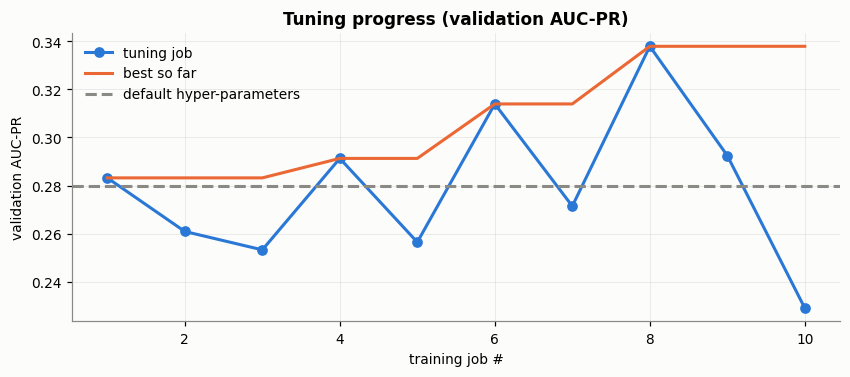

In [10]:
if RUN_TUNING:
    ordered = tuning_results.sort_values("TrainingStartTime")
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.plot(range(1, len(ordered) + 1), ordered.FinalObjectiveValue, "o-", color=BLUE, label="tuning job")
    ax.plot(range(1, len(ordered) + 1), ordered.FinalObjectiveValue.cummax(), color=ORANGE, label="best so far")
    ax.axhline(default_metrics.get("validation:aucpr", np.nan), color=MUTED, ls="--", label="default hyper-parameters")
    ax.set(title="Tuning progress (validation AUC-PR)", xlabel="training job #", ylabel="validation AUC-PR")
    ax.legend()
    plt.show()

### 5.1 Choose the model
The tuned model is adopted only if it beats the default configuration on **validation** AUC-PR; otherwise the simpler default is kept. The chosen hyper-parameters are written to `pipelines/best_hyperparameters.json` (committed to GitHub) so that the CI/CD pipeline retrains with exactly the same settings.

In [9]:
default_score = default_metrics.get("validation:aucpr", 0.0)
if RUN_TUNING and tuning_results.FinalObjectiveValue.iloc[0] > default_score:
    best_job_name = tuner.best_training_job()
    chosen = "tuned"
    best_params = {k: float(tuning_results.iloc[0][k]) for k in
                   ("eta", "min_child_weight", "subsample", "colsample_bytree", "gamma", "lambda", "alpha")}
    best_params["max_depth"] = int(tuning_results.iloc[0]["max_depth"])
else:
    best_job_name, chosen, best_params = default_job["TrainingJobName"], "default", {}

best_job = sm_client.describe_training_job(TrainingJobName=best_job_name)
model_data = best_job["ModelArtifacts"]["S3ModelArtifacts"]
(Path.cwd().parent / "pipelines" / "best_hyperparameters.json").write_text(json.dumps(best_params, indent=2) + "\n")
print(f"Chosen: {chosen} model from job {best_job_name}")
print(f"Validation AUC-PR: default {default_score:.4f}"
      + (f" | best tuned {tuning_results.FinalObjectiveValue.iloc[0]:.4f}" if RUN_TUNING else ""))
print("Hyper-parameters:", json.dumps({**config.DEFAULT_HYPERPARAMETERS, **best_params}, indent=1))

Chosen: tuned model from job ct-xgb-tune-261017-2220-008-9f779cba
Validation AUC-PR: default 0.2797 | best tuned 0.3379
Hyper-parameters: {
 "objective": "binary:logistic",
 "eval_metric": "aucpr",
 "num_round": 400,
 "early_stopping_rounds": 40,
 "max_depth": 6,
 "eta": 0.044241396722974426,
 "subsample": 0.5167504191000817,
 "colsample_bytree": 0.45223113672559395,
 "min_child_weight": 1.3608051865732016,
 "gamma": 2.9455573066665357,
 "lambda": 2.2852990661057127,
 "scale_pos_weight": 5,
 "alpha": 0.11359090013332653
}


## 6. Evaluation on the untouched test year (2020)
The chosen model artefact is downloaded and scored locally with the same XGBoost version the container uses.

**Operating thresholds are set from analyst capacity, not from 0.5.** A security team can review only so many alerts per day, so on the validation year we pick the score cut-off that produces:
* **MEDIUM** = 5 alerts/day → analyst queue,
* **HIGH** = 1 alert/day → page the on-call engineer.

These thresholds are then applied unchanged to 2020.

In [10]:
local_model_dir = DATA_DIR / "model"
local_model_dir.mkdir(exist_ok=True)
ctx.session.download_data(str(local_model_dir), bucket=model_data.split("/")[2], key_prefix="/".join(model_data.split("/")[3:]))
booster = model.load_booster(model.extract_model(local_model_dir / "model.tar.gz", local_model_dir))

scores = {name: model.predict(booster, X[name]) for name in ("validation", "test")}
report = evaluation.evaluation_report(
    val_y=y["validation"], val_scores=scores["validation"], val_times=splits["validation"].window_start,
    test_y=y["test"], test_scores=scores["test"], test_times=splits["test"].window_start)
thresholds = report["thresholds"]

summary = pd.DataFrame({"validation 2019 (MEDIUM)": report["validation"],
                        "test 2020 (MEDIUM)": report["test_medium"],
                        "test 2020 (HIGH)": report["test_high"]}).T
print("Thresholds:", {k: round(v, 4) for k, v in thresholds.items()},
      f"| test alerts/day at MEDIUM: {report['test_alerts_per_day_medium']:.1f}")
summary[["rows", "positives", "prevalence", "roc_auc", "average_precision", "ap_lift", "threshold",
         "precision", "recall", "f1", "true_positives", "false_positives"]].round(4)

Thresholds: {'medium': 0.3338, 'high': 0.3614} | test alerts/day at MEDIUM: 3.5


,rows,positives,prevalence,roc_auc,average_precision,ap_lift,threshold,precision,recall,f1,true_positives,false_positives
validation 2019 (MEDIUM),21855.0,68.0,0.0031,0.8803,0.3685,118.4412,0.3338,0.0191,0.5147,0.0368,35.0,1799.0
test 2020 (MEDIUM),17908.0,101.0,0.0056,0.9587,0.3312,58.7258,0.3338,0.0782,0.7525,0.1417,76.0,896.0
test 2020 (HIGH),17908.0,101.0,0.0056,0.9587,0.3312,58.7258,0.3614,0.2124,0.7129,0.3273,72.0,267.0


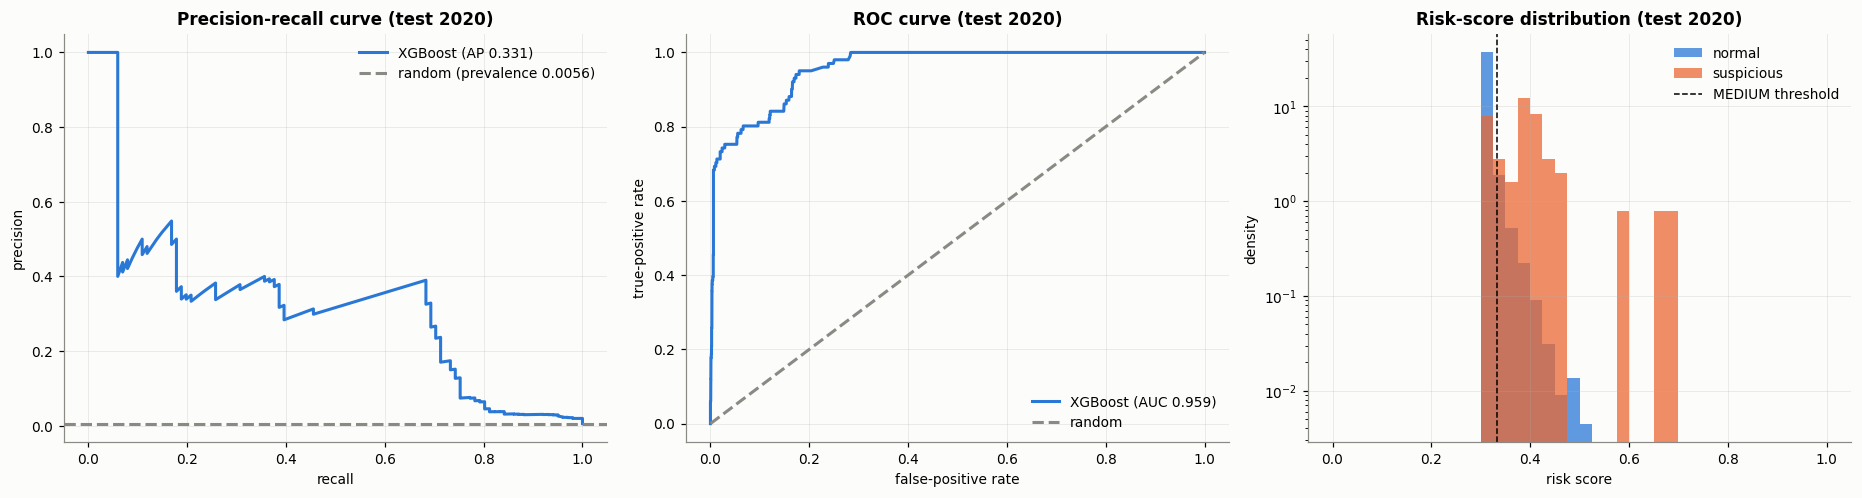

In [11]:
y_test, s_test = y["test"], scores["test"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

precision, recall, _ = precision_recall_curve(y_test, s_test)
axes[0].plot(recall, precision, color=BLUE, label=f"XGBoost (AP {report['test_medium']['average_precision']:.3f})")
axes[0].axhline(y_test.mean(), color=MUTED, ls="--", label=f"random (prevalence {y_test.mean():.4f})")
axes[0].set(title="Precision-recall curve (test 2020)", xlabel="recall", ylabel="precision")
axes[0].legend()

fpr, tpr, _ = roc_curve(y_test, s_test)
axes[1].plot(fpr, tpr, color=BLUE, label=f"XGBoost (AUC {report['test_medium']['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, ls="--", label="random")
axes[1].set(title="ROC curve (test 2020)", xlabel="false-positive rate", ylabel="true-positive rate")
axes[1].legend()

bins = np.linspace(0, 1, 41)
axes[2].hist(s_test[y_test == 0], bins=bins, color=NORMAL, alpha=0.75, density=True, label="normal")
axes[2].hist(s_test[y_test == 1], bins=bins, color=SUSPICIOUS, alpha=0.75, density=True, label="suspicious")
axes[2].axvline(thresholds["medium"], color="black", lw=1, ls="--", label="MEDIUM threshold")
axes[2].set(title="Risk-score distribution (test 2020)", xlabel="risk score", ylabel="density", yscale="log")
axes[2].legend()
plt.tight_layout()
plt.show()

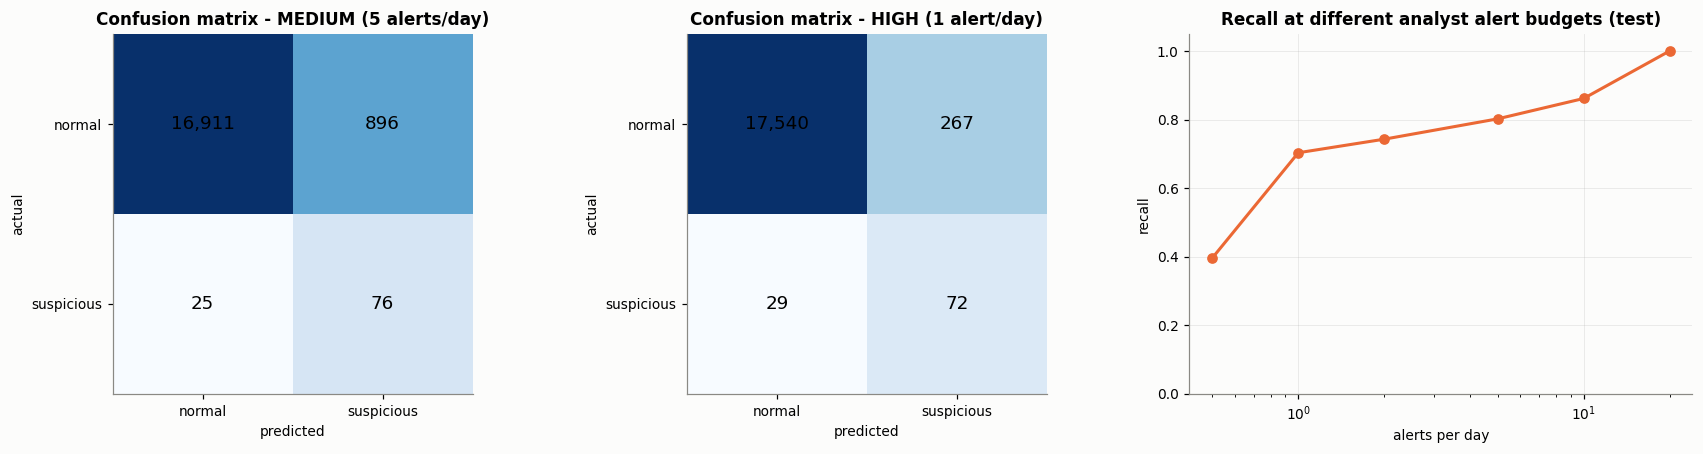

,alerts_per_day,threshold,alerts,precision,recall
0,0.5,0.3925,140,0.2857,0.3960
1,1.0,0.3654,281,0.2527,0.7030
2,2.0,0.3454,564,0.1330,0.7426
3,5.0,0.3243,1406,0.0576,0.8020
4,10.0,0.3147,2817,0.0309,0.8614
5,20.0,0.3095,5881,0.0172,1.0000


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, key, label in ((axes[0], "test_medium", "MEDIUM (5 alerts/day)"), (axes[1], "test_high", "HIGH (1 alert/day)")):
    m = report[key]
    matrix = np.array([[m["true_negatives"], m["false_positives"]], [m["false_negatives"], m["true_positives"]]])
    ax.imshow(np.log1p(matrix), cmap="Blues")
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, f"{value:,}", ha="center", va="center", fontsize=12)
    ax.set(title=f"Confusion matrix - {label}", xticks=[0, 1], yticks=[0, 1], xlabel="predicted", ylabel="actual")
    ax.set_xticklabels(["normal", "suspicious"])
    ax.set_yticklabels(["normal", "suspicious"])
    ax.grid(False)

curve = evaluation.budget_curve(y_test, s_test, splits["test"].window_start)
axes[2].plot(curve.alerts_per_day, curve.recall, "o-", color=ORANGE)
axes[2].set(title="Recall at different analyst alert budgets (test)", xlabel="alerts per day", ylabel="recall", xscale="log", ylim=(0, 1.05))
plt.tight_layout()
plt.show()
curve.round(4)

**How to read these results (test year 2020, never used for any decision).**
* **ROC-AUC 0.959 and average precision 0.331 = 59× the base rate (0.56 %).** On validation (2019) the same model reaches ROC-AUC 0.880 / AP 0.369 — the test year is *not* easier for the model's ranking, so there is no sign of over-fitting to the tuning period.
* **MEDIUM threshold (set for 5 alerts/day on 2019): 3.5 alerts/day in 2020, catching 76 of 101 suspicious windows (recall 75 %).**
* **HIGH threshold (1 alert/day on 2019): ~1.2 alerts/day in 2020, recall 71 % at 21 % precision** — roughly one in five pages is a true policy-flagged window, versus 1 in 180 by chance.
* The alert-budget curve shows the operating trade-off: **1 alert/day already gives 70 % recall**, and 20 alerts/day catch every suspicious window.
* Scores sit in a narrow band (≈ 0.30–0.70) because the tuned model is strongly regularised (`gamma` ≈ 2.9) and trained with `scale_pos_weight = 5`. They are therefore a **ranking**, not calibrated probabilities — which is exactly why thresholds come from analyst capacity rather than a fixed 0.5.

Absolute precision is low *by construction* (positives are < 1 % of windows and labels are rule-based proxies), so the useful question is *"what share of suspicious windows does an analyst see when reviewing N alerts per day?"*

### 6.1 Comparison with baselines on the test year

In [13]:
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.1, max_iter=2000)).fit(X["train"], y["train"])
test_scores = {"XGBoost (production)": s_test,
               "Logistic regression": lr.predict_proba(X["test"])[:, 1],
               "Rule: write_rate_current": X["test"]["write_rate_current"].to_numpy(),
               "Prior only": np.full(len(y_test), y["train"].mean())}
comparison = pd.DataFrame({name: {"ROC-AUC": roc_auc_score(y_test, s), "AP": average_precision_score(y_test, s)}
                           for name, s in test_scores.items()}).T
comparison["AP lift"] = comparison["AP"] / y_test.mean()
comparison.round(4)

,ROC-AUC,AP,AP lift
XGBoost (production),0.9587,0.3312,58.7258
Logistic regression,0.8733,0.0463,8.2165
Rule: write_rate_current,0.7953,0.0290,5.1402
Prior only,0.5000,0.0056,1.0000


### 6.2 What drives the predictions?
*Gain* = how much each feature improves the trees' splits. *Mean |contribution|* = the exact per-prediction (SHAP / TreeSHAP) contribution averaged over the test year — this is also what an analyst would see as the explanation of a single alert.

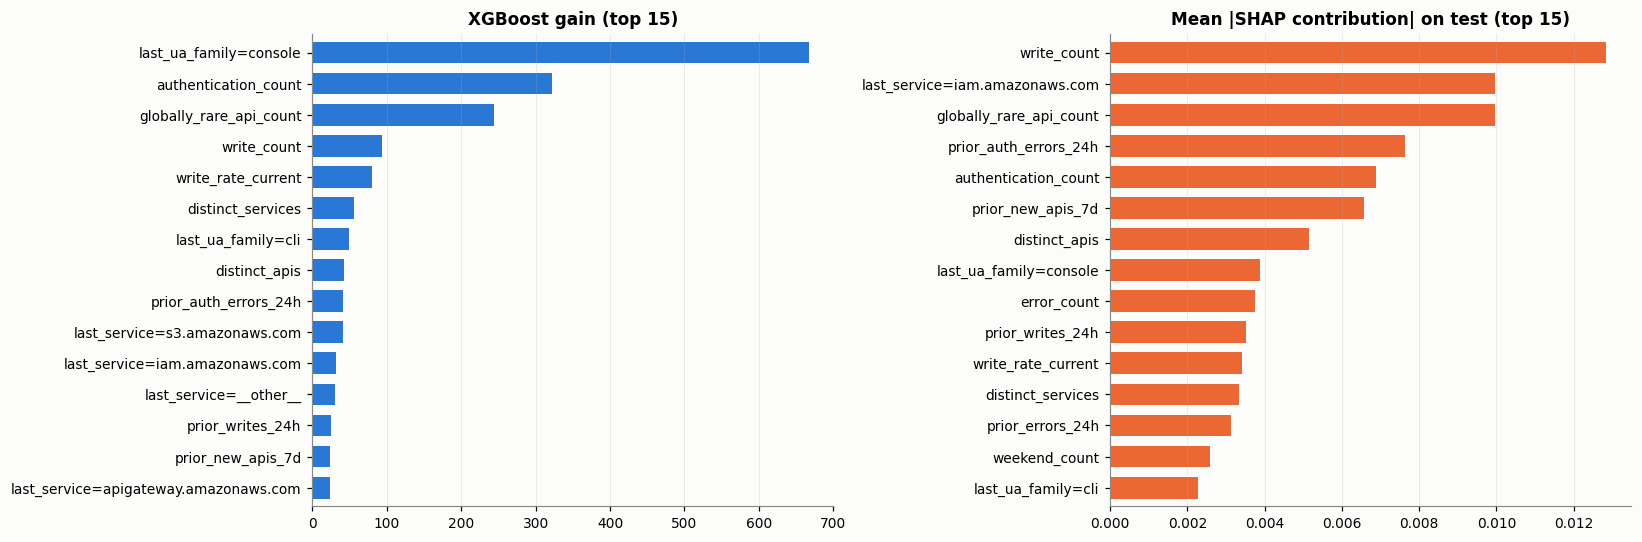

Highest-risk test window: actor=arn:aws:iam::811596193553:root | 2020-05-22 18:05:00+00:00 | score=0.677 | label=1


,contribution to log-odds
authentication_count,0.682
last_ua_family=console,0.120
write_count,0.102
globally_rare_api_count,0.094
distinct_services,0.092
distinct_apis,0.092


In [14]:
import xgboost as xgb

names = encoder.feature_names
gain = pd.Series(booster.get_score(importance_type="gain")).rename(lambda k: names[int(k[1:])]).sort_values()
contributions = booster.predict(xgb.DMatrix(X["test"].to_numpy(dtype=float)), pred_contribs=True)[:, :-1]
shap_importance = pd.Series(np.abs(contributions).mean(axis=0), index=names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
gain.tail(15).plot(kind="barh", ax=axes[0], color=BLUE, width=0.7, title="XGBoost gain (top 15)")
shap_importance.tail(15).plot(kind="barh", ax=axes[1], color=ORANGE, width=0.7, title="Mean |SHAP contribution| on test (top 15)")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

top = int(np.argmax(s_test))
explanation = pd.Series(contributions[top], index=names).sort_values(key=np.abs, ascending=False).head(6)
print(f"Highest-risk test window: actor={splits['test'].actor_id.iloc[top]} | {splits['test'].window_start.iloc[top]} "
      f"| score={s_test[top]:.3f} | label={y_test[top]}")
explanation.round(3).to_frame("contribution to log-odds")

### 6.3 Stability over time (test year, month by month)

In [15]:
by_month = pd.DataFrame({"month": splits["test"].window_start.dt.strftime("%Y-%m"), "y": y_test,
                         "alert": (s_test >= thresholds["medium"]).astype(int)})
monthly = by_month.groupby("month").agg(windows=("y", "size"), suspicious=("y", "sum"), alerts=("alert", "sum"))
monthly["caught"] = by_month[by_month.y == 1].groupby("month").alert.sum().reindex(monthly.index).fillna(0).astype(int)
monthly["recall"] = (monthly.caught / monthly.suspicious.replace(0, np.nan)).round(3)
monthly

,windows,suspicious,alerts,caught,recall
month,,,,,
2020-01,1750,15,108,4,0.267
2020-02,1878,0,62,0,NaN
2020-03,2423,2,106,2,1.000
2020-04,2063,17,109,4,0.235
2020-05,1904,2,75,2,1.000
2020-06,1769,1,74,1,1.000
2020-07,1932,2,87,2,1.000
2020-08,1709,22,91,22,1.000
2020-09,1957,33,146,32,0.970


**Observations.**
* XGBoost is clearly better than all baselines on 2020: **AP 0.331 vs 0.046 for logistic regression and 0.029 for the best one-line rule** (ROC-AUC 0.959 vs 0.873 / 0.795). The non-linear model is justified.
* The model relies on *behaviour*, not on the label rules: console sessions with authentication activity, write calls, **globally rare APIs**, prior authorisation failures and newly used APIs — consistent with the EDA in notebooks 01–02. The highest-risk 2020 window (root account, 22 May 2020) is driven mainly by `authentication_count`.
* **Recall is uneven over the year:** near-perfect in Mar and May–Oct (incl. the Aug–Sep public-exposure burst, 54 of 55 caught), but only 4 of 15 in January and 4 of 17 in April. Positives are few and bunched in a handful of actors, so monthly numbers are noisy; this is the main limitation to state in the design document, together with the weak-label caveat.

In [16]:
gate = evaluation.quality_gate({"roc_auc": report["metrics"]["test_roc_auc"], "ap_lift": report["metrics"]["test_ap_lift"]})
report["quality_gate"] = gate
report["chosen_training_job"] = best_job_name
report["hyperparameters"] = {**config.DEFAULT_HYPERPARAMETERS, **best_params}

evaluation_path = DATA_DIR / "evaluation.json"
evaluation_path.write_text(json.dumps(report, indent=2, default=float))
evaluation_uri = ctx.session.upload_data(str(evaluation_path), bucket=ctx.bucket, key_prefix=ctx.prefix("training") + "/evaluation")
aws.save_state(ctx, best_training_job=best_job_name, model_data=model_data, evaluation_uri=evaluation_uri,
               thresholds=thresholds, image_uri=image_uri)
print("Quality gate:", "PASSED" if gate["passed"] else "FAILED", gate["checks"])
print("Evaluation report:", evaluation_uri)

Quality gate: PASSED {'roc_auc >= 0.8': True, 'ap_lift >= 5.0': True}
Evaluation report: s3://sagemaker-us-east-1-674905628044/cloudtrail-mlops/training/evaluation/evaluation.json


## 8. Summary
* Single **XGBoost** binary classifier trained with a SageMaker training job and tuned with **SageMaker Automatic Model Tuning** (10 jobs, Bayesian search): validation AUC-PR improved from **0.280 (default) to 0.338 (tuned)**; the tuned model was adopted.
* Untouched 2020 test year: **ROC-AUC 0.959, AP 0.331 (59× lift), recall 75 % at 3.5 alerts/day** — far better than logistic regression, rule and prior baselines.
* Release gate (ROC-AUC ≥ 0.80 and AP lift ≥ 5×): **PASSED**. Model artefact, `evaluation.json` and the chosen hyper-parameters (`pipelines/best_hyperparameters.json`) are stored for the Model Registry (notebook 04) and the CI/CD pipeline (notebook 06).

> **Commit** `pipelines/best_hyperparameters.json` together with this notebook.